In [291]:
import numpy as np
import matplotlib.pyplot as plt

In [292]:
def gershgorin_disks(A):
  """Computes the Gershgorin disks for a square matrix A."""
  n = A.shape[0]
  centers = np.diag(A)    # Diagonal elements
  radii = np.sum(np.abs(A), axis=1) - np.abs(centers)    # Row sum excluding diagonal
  return centers, radii

In [293]:
def verify_gershgorin(A):
  """Verifies if the eigenvalues of A lie within the Gershgorin disks."""
  centers, radii = gershgorin_disks(A)
  eigenvalues = np.linalg.eigvals(A)
  print("Eigenvalues of A: ", eigenvalues)
  for i, eig in enumerate(eigenvalues):
    is_inside = any(abs(eig - centers[j]) <= radii[j] for j in range(len(centers)))
    print(f"Eigenvalue {eig}: {'Inside' if is_inside else 'Outside'} Gershgorin Disks")

In [294]:
def plot_gershgorin(A):
  """Plots the Gershgorin disks along with the eigenvalues of A."""
  centers, radii = gershgorin_disks(A)
  eigenvalues = np.linalg.eigvals(A)
  fig, ax = plt.subplots()
  # Plot Gershgorin circles
  for i in range(len(centers)):
    circle = plt.Circle((centers[i].real, centers[i].imag), radii[i], color='b', fill=False, linestyle='dashed')
    ax.add_patch(circle)
    plt.plot(centers[i].real, centers[i].imag, 'bo', markersize=3)    # Center of the disk
  # Plot eigenvalues
  plt.scatter(eigenvalues.real, eigenvalues.imag, color='r', label='Eigenvalues', marker='x')
  ax.set_xlabel('Real')
  ax.set_ylabel('Imaginary')
  ax.axhline(0, color='black', linewidth=0.5)
  ax.axvline(0, color='black', linewidth=0.5)
  ax.set_title('Gershgorin Disks & Eigenvalues')
  ax.set_xlim(min(centers) - max(radii) - 1, max(centers) + max(radii) + 1)
  ax.set_ylim(-max(radii) - 1, max(radii) + 1)
  ax.set_aspect('equal')
  ax.legend()
  ax.grid(True)
  plt.show()

In [295]:
# Example Usage
# A = np.array([[2, -1, -2],
#               [1, 0, -1],
#               [2, 1, 1]]. dtype=float)
A = np.array([[2, -1, -2, 0],
              [1, 0, -1, 1],
              [2, 1, 1, 0],
              [0, 2, 0, -1]], dtype=float)

Matrix A:
 [[ 2. -1. -2.  0.]
 [ 1.  0. -1.  1.]
 [ 2.  1.  1.  0.]
 [ 0.  2.  0. -1.]]
Eigenvalues of A:  [-1.86518073+0.j          1.36775965+2.29091325j  1.36775965-2.29091325j
  1.12966142+0.j        ]
Eigenvalue (-1.865180727779454+0j): Inside Gershgorin Disks
Eigenvalue (1.3677596524734907+2.2909132470899656j): Inside Gershgorin Disks
Eigenvalue (1.3677596524734907-2.2909132470899656j): Inside Gershgorin Disks
Eigenvalue (1.1296614228324706+0j): Inside Gershgorin Disks


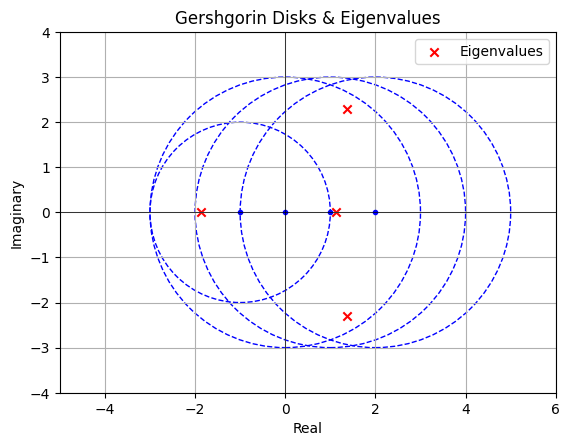

In [296]:
print("Matrix A:\n", A)
verify_gershgorin(A)
plot_gershgorin(A)